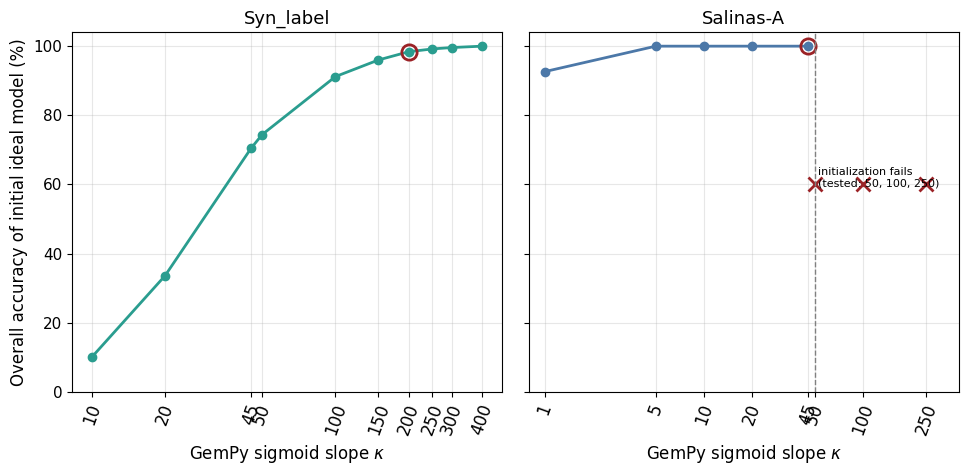

In [20]:
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({"font.size": 15, "axes.titlesize": 13, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11})

# ---- data: edit here ----
# Syn_label: initial-model overall accuracy (%) vs kappa
kappa_syn = np.array([10, 20, 45, 50, 100, 150, 200, 250, 300, 400])
oa_syn    = np.array([10, 33.6, 70.4, 74.4, 91.2, 96, 98.4, 99.2, 99.6, 100])
kappa_used_syn = 200          # value used in the experiments (circled)

# Salinas-A: initial-model OA (%) vs kappa; larger values failed to initialize
kappa_sal = np.array([1, 5, 10, 20, 45])
oa_sal    = np.array([92.62, 100, 100, 100, 100])
kappa_used_sal = 45
kappa_fail_sal = [50, 100, 250]   # tested, failed at initialization
# -------------------------

c_line, c_mark = "#2a9d8f", "#9b2226"

fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

# Syn_label panel
a = ax[0]
a.semilogx(kappa_syn, oa_syn, "-o", color=c_line, lw=2)
a.plot(kappa_used_syn, oa_syn[kappa_syn == kappa_used_syn], "o",
       color=c_mark, ms=11, mfc="none", mew=2)
a.set_xticks(kappa_syn)
a.set_xticklabels(kappa_syn, fontsize=12)
a.set_xticklabels(kappa_syn, rotation=70)
a.minorticks_off()
a.set_title("Syn_label")
a.set_xlabel(r"GemPy sigmoid slope $\kappa$")
a.set_ylabel("Overall accuracy of initial ideal model (%)")
a.grid(alpha=0.3)

# Salinas-A panel
b = ax[1]
b.semilogx(kappa_sal, oa_sal, "-o", color="#4c78a8", lw=2)
b.plot(kappa_used_sal, oa_sal[kappa_sal == kappa_used_sal], "o",
       color=c_mark, ms=11, mfc="none", mew=2)
for kf in kappa_fail_sal:                       # failed values: crosses at y = 60
    b.plot(kf, 60, "x", color=c_mark, ms=10, mew=2)
b.axvline(min(kappa_fail_sal), color="gray", ls="--", lw=1)
b.text(min(kappa_fail_sal) * 1.05, 62,
       "initialization fails\n(tested: " + ", ".join(map(str, kappa_fail_sal)) + ")",
       fontsize=8, va="center")
ticks = sorted(set(kappa_sal.tolist() + kappa_fail_sal))
b.set_xticks(ticks)
b.set_xticklabels(ticks, fontsize=12)
b.set_xticklabels(ticks, rotation=70)
b.minorticks_off()
b.set_xlim(0.8, 400)
b.set_ylim(0, 104)
b.set_title("Salinas-A")
b.set_xlabel(r"GemPy sigmoid slope $\kappa$")
b.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("oa_vs_kappa.pdf")            # vector for the paper
plt.savefig("oa_vs_kappa.png", dpi=300)   # raster copy
plt.show()